# 🎛️ Lesson 06 · Optimizers, Learning Rates, Epochs & Batch Sizes

*“Training a neural network is 20 % architecture and 80 % getting these four knobs right.”*

| ⏱ Time | 🎚 Level | 🗓 Suggested day | 📚 You should know |
|:--|:--|:--|:--|
| ~100 min | 🟡 Intermediate | Day 5 | Lessons 04–05 |

## 🎯 Learning objectives
By the end of this lesson you will be able to:

- Implement **SGD, momentum, RMSProp and Adam** from scratch and see *why* they differ
- Find a good **learning rate** with a sweep and the **LR range test**
- Explain **epochs, iterations and batch size** and compute how many updates training performs
- Measure how **batch size** changes speed, noise and accuracy
- Recognise **under- and over-training** in learning curves
- Diagnose training problems from symptoms (a field guide)

## 🗺 Roadmap
1. Vocabulary: epoch, batch, iteration
2. Optimisers on a ravine
3. Optimisers on a real network
4. Learning rate: the master knob
5. Batch size
6. Epochs & overfitting
7. Symptom field guide
8. Problems

## ⚙️ Setup
Run this cell first. It loads our libraries and the course helper module (`utils/dlcourse.py`).

In [1]:
import sys; sys.path.append("..")          # so we can import the course helper library
import numpy as np
import matplotlib.pyplot as plt
from utils import dlcourse as dl
import torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
dl.set_seed(42)                          # reproducible randomness
%matplotlib inline

---
## 📖 1. Vocabulary: batch, iteration, epoch

| Term | Meaning | Analogy 🌽 |
|:--|:--|:--|
| **Batch size** `B` | Examples used for *one* gradient estimate / weight update | Taste a spoonful of the stew before adjusting the salt |
| **Iteration (step)** | One weight update (forward + backward on one batch) | One adjustment |
| **Epoch** | One full pass over the training set | Tasting the whole pot once |

$$\text{steps per epoch}=\left\lceil \frac{N}{B}\right\rceil\qquad\text{total steps}=\text{steps per epoch}\times\text{epochs}$$

**Worked example.** MNIST has $N=60{,}000$ images. With $B=128$: $\lceil 60000/128\rceil=469$ steps per epoch. Train for 10 epochs → **4,690 weight updates**.
With $B=1{,}000$ the same 10 epochs make only 600 updates. *Same amount of data seen, far fewer chances to learn.*

Three flavours of gradient descent differ only in $B$:

| Name | Batch size | Gradient quality | Speed per update |
|:--|:--|:--|:--|
| **Batch GD** | $B=N$ (everything) | Exact, smooth | Slow, memory-hungry |
| **Stochastic GD (SGD)** | $B=1$ | Very noisy | Fast but can't use hardware parallelism |
| **Mini-batch GD** ⭐ | $B=32\ldots256$ typical | Good estimate, a little noise | Fast & GPU-friendly |

*(In deep-learning talk, "SGD" nearly always means mini-batch SGD.)*

---
## 🏞 2. Optimisers on a ravine

The plain update $\theta\leftarrow\theta-\eta g$ has a weakness in **ravines**: long narrow valleys, steep in one direction and shallow in another (very common in deep nets). SGD bounces across the steep walls while crawling along the floor. Better optimisers fix this:

| Optimiser | Update | Idea |
|:--|:--|:--|
| **SGD** | $\theta\leftarrow\theta-\eta\,g$ | Walk downhill |
| **Momentum** | $v\leftarrow\beta v+g;\ \theta\leftarrow\theta-\eta v$ | A rolling ball: builds speed along consistent directions, cancels zig-zags |
| **RMSProp** | $s\leftarrow\rho s+(1-\rho)g^2;\ \theta\leftarrow\theta-\eta\,g/(\sqrt{s}+\epsilon)$ | Give each parameter its **own** step size: shrink where gradients are large, grow where small |
| **Adam** ⭐ | momentum $m$ + RMSProp $v$ (with bias correction $\hat m=m/(1-\beta_1^t)$, $\hat v=v/(1-\beta_2^t)$): $\theta\leftarrow\theta-\eta\,\hat m/(\sqrt{\hat v}+\epsilon)$ | Best of both; robust defaults ($\eta=10^{-3}$, $\beta_1=.9$, $\beta_2=.999$) |

Let's code all four from scratch and race them on the ravine $f(x,y)=\tfrac12(x^2+100y^2)$: 100× steeper in $y$ than $x$:

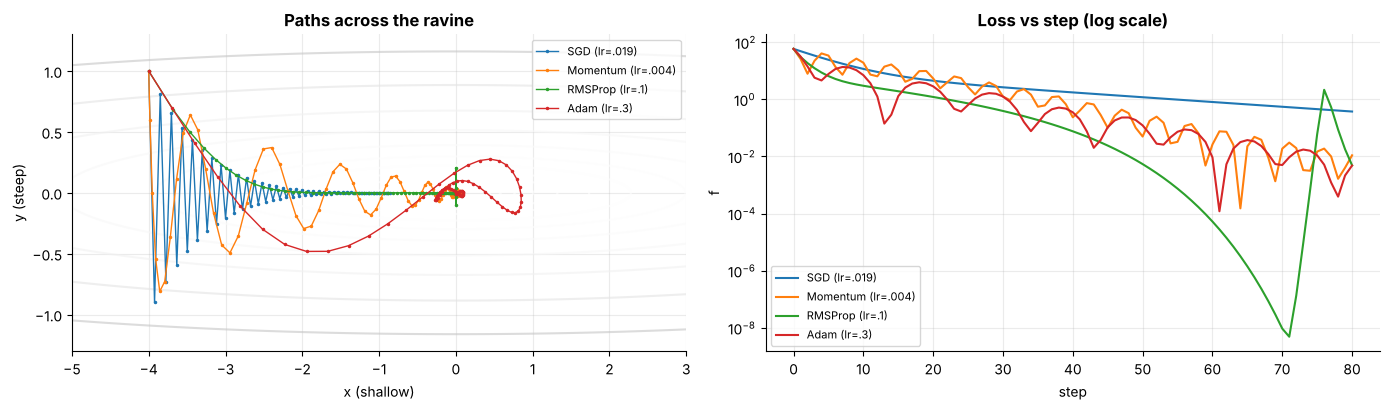

SGD (lr=.019)        final loss after 80 steps: 0.3716
Momentum (lr=.004)   final loss after 80 steps: 0.0109
RMSProp (lr=.1)      final loss after 80 steps: 0.0049
Adam (lr=.3)         final loss after 80 steps: 0.0048


In [2]:
A = np.array([1.0, 100.0])
f = lambda p: 0.5 * (A * p ** 2).sum()
grad = lambda p: A * p

def sgd(lr):
    return lambda p, g, st, t: p - lr * g

def momentum(lr, beta=0.9):
    def update(p, g, st, t):
        st["v"] = beta * st.get("v", 0) + g
        return p - lr * st["v"]
    return update

def rmsprop(lr, rho=0.9, eps=1e-8):
    def update(p, g, st, t):
        st["s"] = rho * st.get("s", 0) + (1 - rho) * g ** 2
        return p - lr * g / (np.sqrt(st["s"]) + eps)
    return update

def adam(lr, b1=0.9, b2=0.999, eps=1e-8):
    def update(p, g, st, t):
        st["m"] = b1 * st.get("m", 0) + (1 - b1) * g
        st["v"] = b2 * st.get("v", 0) + (1 - b2) * g ** 2
        m_hat, v_hat = st["m"] / (1 - b1 ** t), st["v"] / (1 - b2 ** t)      # bias correction
        return p - lr * m_hat / (np.sqrt(v_hat) + eps)
    return update

def run(update, p0=(-4.0, 1.0), steps=80):
    p, state, path = np.array(p0), {}, [np.array(p0)]
    for t in range(1, steps + 1):
        p = update(p, grad(p), state, t); path.append(p.copy())
    return np.array(path)

runs = {"SGD (lr=.019)": run(sgd(.019)), "Momentum (lr=.004)": run(momentum(.004)),
        "RMSProp (lr=.1)": run(rmsprop(.1)), "Adam (lr=.3)": run(adam(.3))}

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
xx, yy = np.meshgrid(np.linspace(-5, 3, 200), np.linspace(-1.3, 1.3, 200))
ax[0].contour(xx, yy, 0.5 * (xx ** 2 + 100 * yy ** 2), levels=np.logspace(-1, 2.3, 15), cmap="Greys", alpha=.6)
for (name, P), c in zip(runs.items(), ["C0", "C1", "C2", "C3"]):
    ax[0].plot(P[:, 0], P[:, 1], ".-", c=c, ms=3, label=name, lw=1)
    ax[1].semilogy([f(p) + 1e-12 for p in P], c=c, label=name)
ax[0].legend(fontsize=8); ax[0].set(title="Paths across the ravine", xlabel="x (shallow)", ylabel="y (steep)")
ax[1].set(title="Loss vs step (log scale)", xlabel="step", ylabel="f"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
for name, P in runs.items(): print(f"{name:20s} final loss after 80 steps: {f(P[-1]):.4f}")

**Reading the picture:** SGD *can't* raise its learning rate (the steep $y$ direction would explode), so it crawls along $x$. Momentum builds speed along $x$ and damps the $y$ wobble. RMSProp and Adam rescale each coordinate separately, so they shoot along the valley floor.

🤔 **Pause and think.** Adam adds *bias correction* ($1-\beta^t$). At step $t=1$ with $m_0=0$, what would $m_1$ be without correction? Why is that a problem?

<details><summary>Click to reveal the answer</summary>

$m_1=(1-\beta_1)g=0.1\,g$: only 10 % of the true gradient, because the average started at zero. Dividing by $1-\beta_1^1=0.1$ fixes it to $g$. Without correction the first steps would be tiny and biased toward zero.

</details>

---
## 🧪 3. The optimisers on a real network

Now the same race, but with PyTorch's built-in optimisers training a small MNIST classifier. We'll reuse this tiny experiment kit throughout the lesson.

SGD lr=.1              final val acc 0.922   (0.8s)


SGD+momentum lr=.05    final val acc 0.939   (0.7s)


RMSprop lr=1e-3        final val acc 0.932   (0.9s)


Adam lr=1e-3           final val acc 0.926   (1.0s)


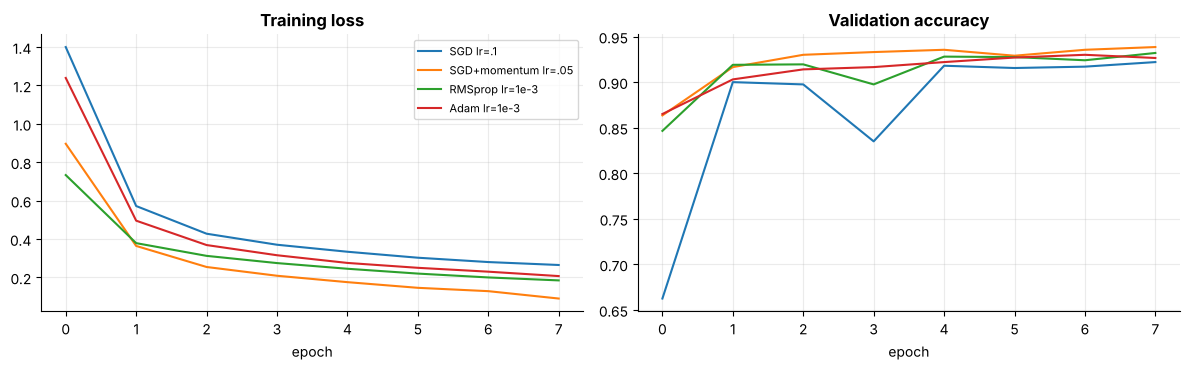

In [3]:
def get_loaders(n_train=5000, n_val=2000, batch_size=64):
    xtr, ytr, xva, yva = dl.load_mnist(n_train=n_train, n_test=n_val, flatten=True)
    tr = DataLoader(TensorDataset(torch.tensor(xtr), torch.tensor(ytr)), batch_size=batch_size, shuffle=True)
    va = DataLoader(TensorDataset(torch.tensor(xva), torch.tensor(yva)), batch_size=512)
    return tr, va

def make_model(seed=0):
    torch.manual_seed(seed)                                    # same starting weights for a FAIR race
    return nn.Sequential(nn.Linear(784, 64), nn.ReLU(), nn.Linear(64, 10))

cpu = torch.device("cpu")
tr, va = get_loaders()
optimizers = {
    "SGD lr=.1":            lambda p: torch.optim.SGD(p, lr=0.1),
    "SGD+momentum lr=.05":  lambda p: torch.optim.SGD(p, lr=0.05, momentum=0.9),
    "RMSprop lr=1e-3":      lambda p: torch.optim.RMSprop(p, lr=1e-3),
    "Adam lr=1e-3":         lambda p: torch.optim.Adam(p, lr=1e-3),
}
histories = {}
for name, make_opt in optimizers.items():
    model = make_model()
    histories[name] = dl.fit(model, tr, va, nn.CrossEntropyLoss(), make_opt(model.parameters()), epochs=8, device=cpu, verbose=False)
    print(f"{name:22s} final val acc {histories[name]['val_acc'][-1]:.3f}   ({histories[name]['seconds']:.1f}s)")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for name, h in histories.items():
    ax[0].plot(h["train_loss"], label=name); ax[1].plot(h["val_acc"], label=name)
ax[0].set(title="Training loss", xlabel="epoch"); ax[1].set(title="Validation accuracy", xlabel="epoch"); ax[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

> 🛠 **Pro tip**: **Which optimiser should I use?** Start with **Adam** (or **AdamW**, Adam with proper weight decay) at `lr=1e-3`. It works out of the box on almost everything. **SGD + momentum** often generalises slightly better on image models *when carefully tuned* and is the classic choice for CNNs like ResNet. Don't go optimiser-shopping before you've tuned the learning rate.

---
## 🎚 4. The learning rate: the master knob

If you could tune only one hyperparameter, tune this. Two tools:

**(a) A sweep:** train briefly at many learning rates (log-spaced!) and compare.

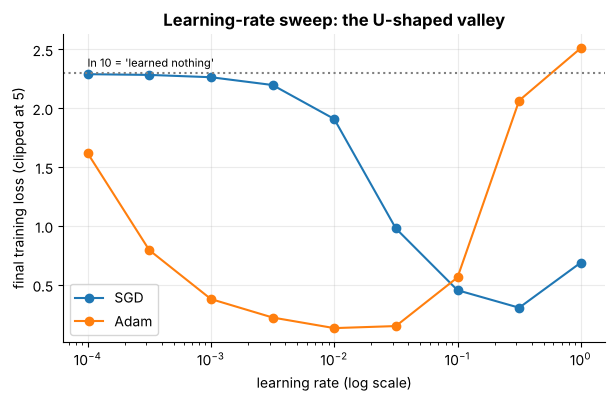

In [4]:
lrs = np.logspace(-4, 0, 9)                      # 0.0001 ... 1.0: always sweep on a LOG scale
results = {"SGD": [], "Adam": []}
tr_small, va_small = get_loaders(n_train=3000, batch_size=64)
for lr in lrs:
    for name in results:
        model = make_model()
        opt = torch.optim.SGD(model.parameters(), lr=lr) if name == "SGD" else torch.optim.Adam(model.parameters(), lr=lr)
        h = dl.fit(model, tr_small, va_small, nn.CrossEntropyLoss(), opt, epochs=4, device=cpu, verbose=False)
        results[name].append(h["train_loss"][-1])

plt.figure(figsize=(7, 4))
for name, vals in results.items():
    plt.semilogx(lrs, np.clip(vals, 0, 5), "o-", label=name)
plt.axhline(np.log(10), c="gray", ls=":"); plt.annotate("ln 10 = 'learned nothing'", (lrs[0], np.log(10) + .05), fontsize=8)
plt.xlabel("learning rate (log scale)"); plt.ylabel("final training loss (clipped at 5)"); plt.legend(); plt.title("Learning-rate sweep: the U-shaped valley")
plt.show()

Both curves are **U-shaped**: too low → hasn't learned yet in our budget; too high → unstable. The best value sits at the bottom, and **SGD and Adam have different sweet spots** (here Adam is happiest around 10⁻³–10⁻², plain SGD around 10⁻¹–3·10⁻¹): never copy a learning rate across optimisers.

**(b) The LR range test** (Leslie Smith): train *once* while the learning rate grows exponentially each step; plot loss vs LR. Pick a value a bit **below the point where loss is lowest, before it blows up.**

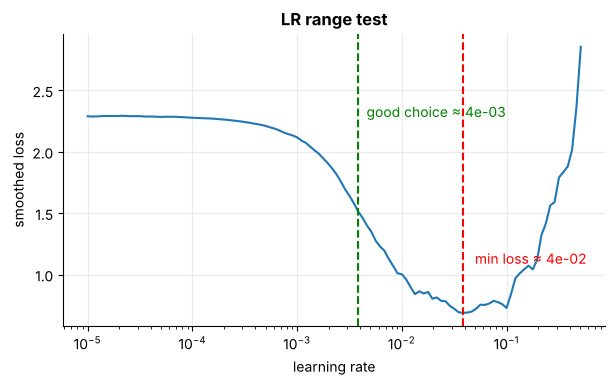

In [5]:
def lr_range_test(lr_min=1e-5, lr_max=1.0, steps=120):
    model = make_model(); loss_fn = nn.CrossEntropyLoss()
    opt = torch.optim.Adam(model.parameters(), lr=lr_min)
    gamma = (lr_max / lr_min) ** (1 / steps)            # multiply the LR by this each step
    lrs, losses, smooth = [], [], None
    data_iter = iter(tr_small)
    for step in range(steps):
        try: xb, yb = next(data_iter)
        except StopIteration: data_iter = iter(tr_small); xb, yb = next(data_iter)
        lr = lr_min * gamma ** step
        for g in opt.param_groups: g["lr"] = lr
        loss = loss_fn(model(xb), yb)
        opt.zero_grad(); loss.backward(); opt.step()
        smooth = loss.item() if smooth is None else 0.9 * smooth + 0.1 * loss.item()
        lrs.append(lr); losses.append(smooth)
        if smooth > 4 * min(losses): break                # diverged: stop
    return np.array(lrs), np.array(losses)

lr_hist, loss_hist = lr_range_test()
plt.figure(figsize=(7, 3.8)); plt.semilogx(lr_hist, loss_hist)
best = lr_hist[np.argmin(loss_hist)]
plt.axvline(best, c="r", ls="--"); plt.axvline(best / 10, c="g", ls="--")
plt.annotate(f"min loss ≈ {best:.0e}", (best, loss_hist.min()), color="r", xytext=(best * 1.3, loss_hist.min() + .4))
plt.annotate(f"good choice ≈ {best / 10:.0e}", (best / 10, loss_hist[np.argmin(np.abs(lr_hist - best / 10))]), color="g", xytext=(best / 10 * 1.2, loss_hist.max() * .8))
plt.xlabel("learning rate"); plt.ylabel("smoothed loss"); plt.title("LR range test"); plt.show()

---
## 📦 5. Batch size

The batch size trades **gradient quality** against **number of updates** and **hardware efficiency**.
Let's train the *same* model for the *same number of epochs* with different batch sizes:

batch     8 | updates  3000 | val acc 0.927 | time   2.7s


batch    32 | updates   750 | val acc 0.928 | time   1.1s


batch   128 | updates   192 | val acc 0.915 | time   0.4s


batch   512 | updates    48 | val acc 0.863 | time   0.2s


batch  2000 | updates    12 | val acc 0.709 | time   0.2s


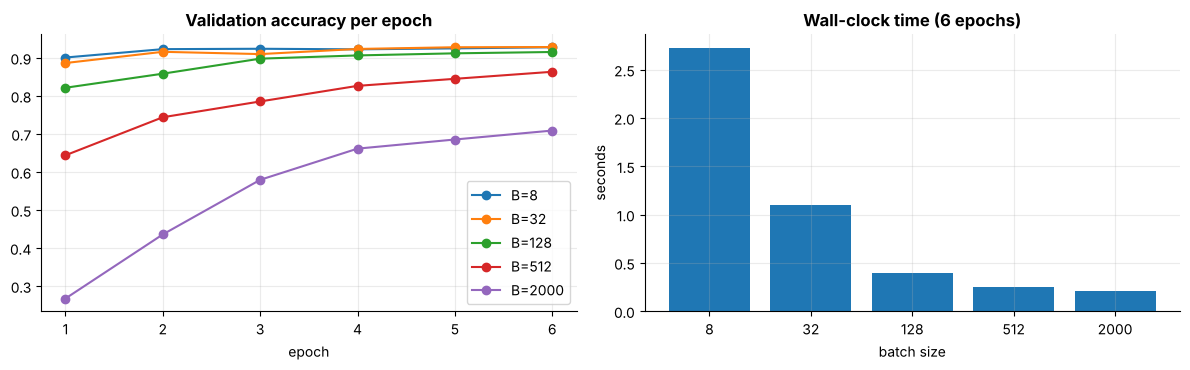

In [6]:
rows = []
for bs in [8, 32, 128, 512, 2000]:
    tr_b, va_b = get_loaders(n_train=4000, batch_size=bs)
    model = make_model()
    h = dl.fit(model, tr_b, va_b, nn.CrossEntropyLoss(), torch.optim.Adam(model.parameters(), lr=1e-3), epochs=6, device=cpu, verbose=False)
    rows.append((bs, len(tr_b) * 6, h["val_acc"][-1], h["seconds"], h["val_acc"]))
    print(f"batch {bs:5d} | updates {len(tr_b) * 6:5d} | val acc {h['val_acc'][-1]:.3f} | time {h['seconds']:5.1f}s")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for bs, upd, acc, sec, curve in rows: ax[0].plot(range(1, 7), curve, "o-", label=f"B={bs}")
ax[0].set(title="Validation accuracy per epoch", xlabel="epoch"); ax[0].legend()
ax[1].bar([str(r[0]) for r in rows], [r[3] for r in rows]); ax[1].set(title="Wall-clock time (6 epochs)", xlabel="batch size", ylabel="seconds")
plt.tight_layout(); plt.show()

**What to notice**
* Tiny batches make *many* noisy updates per epoch → fast progress per epoch, but each update is cheap-and-noisy, and Python overhead makes them slow in wall-clock time on CPU/GPU.
* Huge batches make *few* precise updates → after the same number of epochs they've barely learned (fewer steps!), unless you raise the learning rate (the **linear scaling rule**: ×k batch → ×k learning rate, with warm-up).
* **Practical default: 32–256.** Use the largest that fits in memory and gives stable training; some noise actually helps generalisation.

---
## ⏳ 6. Epochs: under-training vs over-training

How long should you train? Too few epochs → **underfitting** (loss still falling). Too many → **overfitting**: the network starts *memorising* training examples, so training loss keeps falling while **validation loss turns around and rises**. To see it clearly we give a big network very little data:

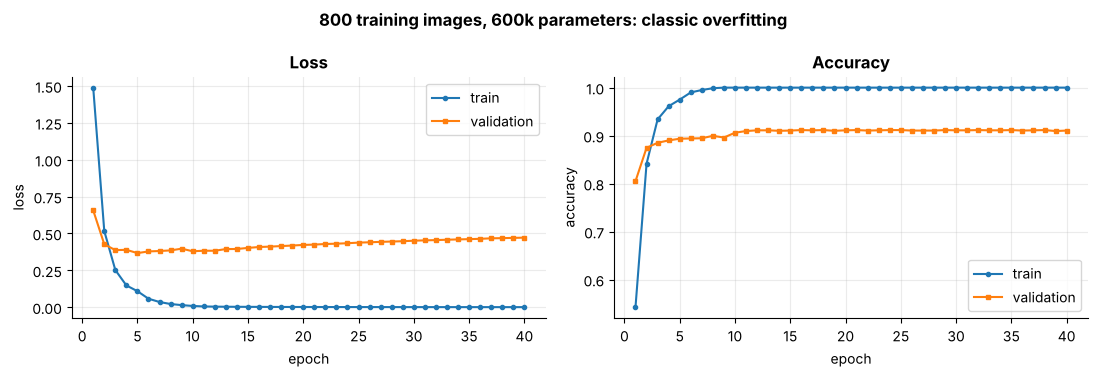

validation loss was lowest at epoch 5; train acc ends at 100.0% but val acc is 91.0%


In [7]:
tr_o, va_o = get_loaders(n_train=800, n_val=2000, batch_size=32)
torch.manual_seed(0)
big = nn.Sequential(nn.Linear(784, 512), nn.ReLU(), nn.Linear(512, 512), nn.ReLU(), nn.Linear(512, 10))
h = dl.fit(big, tr_o, va_o, nn.CrossEntropyLoss(), torch.optim.Adam(big.parameters(), lr=1e-3), epochs=40, device=cpu, verbose=False)
dl.plot_history(h, "800 training images, 600k parameters: classic overfitting")
best_epoch = int(np.argmin(h["val_loss"])) + 1
print(f"validation loss was lowest at epoch {best_epoch}; train acc ends at {h['train_acc'][-1]:.1%} but val acc is {h['val_acc'][-1]:.1%}")

> 💡 **Big idea**: **Rule: judge a model by validation data, never training data.** The gap between the two curves *is* overfitting. The fix is not a fixed number of epochs: it's to *watch the validation loss* and stop when it stops improving (**early stopping**), and to use regularisation (dropout, weight decay, augmentation). All in Lesson 14.

---
## 🩺 7. Field guide: symptoms → remedies

| Symptom (training curves) | Diagnosis | Try |
|:--|:--|:--|
| Loss is `nan`/`inf` or shoots up | LR far too high; exploding gradients | LR ÷ 10; clip gradients; check data for NaNs |
| Loss barely moves (stays ≈ ln k) | LR too low; dead activations; bug | LR × 3; verify you can overfit one batch |
| Loss decreases then bounces/plateaus noisily | LR a bit high | Lower LR or add an LR schedule (Lesson 14) |
| Train & val loss both high and flat | **Underfitting**: model too small / too few epochs | Bigger model, train longer, higher LR |
| Train loss low, val loss high or rising | **Overfitting** | More data/augmentation, dropout, weight decay, early stopping, smaller model |
| Val accuracy jumps around epoch to epoch | Val set small, or LR high | Larger val set; lower LR |
| Training is very slow in wall-clock time | Batch too small / data loading bottleneck | Larger batch; `num_workers`; GPU |

> 🧠 **Professor's tip:** change **one thing at a time**, and log every experiment (what you changed, the curve, the result). Undisciplined tinkering is the biggest time-waster in deep learning.

---
# 🏋️ Practice problems
Work through these in order. Each problem has **hints** (open them one at a time: struggling a little is how learning happens!) and a **self-check cell** that tells you ✅ or ❌. Full solutions live in `../solutions/`.

*Difficulty:* ⭐ warm-up · ⭐⭐ standard · ⭐⭐⭐ challenge

---
### 🧩 Problem 6.1: Count the updates  &nbsp; `⭐`

Write `training_steps(n_samples, batch_size, epochs)` returning `(steps_per_epoch, total_steps)`. The final partial batch **counts** as a step (PyTorch's default `drop_last=False`).

<details><summary>💡 Hint 1</summary>

Use `math.ceil(n_samples / batch_size)`.

</details>

<details><summary>💡 Hint 2</summary>

Total = steps per epoch × epochs.

</details>


In [ ]:
import math

def training_steps(n_samples, batch_size, epochs):
    pass   # return steps_per_epoch, total

In [ ]:
# ▶ self-check (run after you've written your answer)
dl.check("MNIST, B=128, 10 epochs → (469, 4690)", training_steps(60000, 128, 10) == (469, 4690))
dl.check("exact division: 1000/100, 3 epochs → (10, 30)", training_steps(1000, 100, 3) == (10, 30))
dl.check("batch bigger than data → 1 step per epoch", training_steps(50, 64, 4) == (1, 4))

---
### 🧩 Problem 6.2: Momentum from scratch  &nbsp; `⭐⭐`

Implement `momentum_descent(grad, p0, lr, beta, steps)` using the *velocity* form
$v\leftarrow\beta v+g,\ \theta\leftarrow\theta-\eta v$ (start with $v=0$). `p0` and the gradient are NumPy arrays. Return the final parameters.

<details><summary>💡 Hint 1</summary>

Keep a `v = np.zeros_like(p)` before the loop.

</details>

<details><summary>💡 Hint 2</summary>

Inside the loop: `g = grad(p); v = beta * v + g; p = p - lr * v`.

</details>


In [ ]:
def momentum_descent(grad, p0, lr, beta, steps):
    pass

In [ ]:
# ▶ self-check (run after you've written your answer)
A = np.array([1.0, 100.0]); g = lambda p: A * p
one = momentum_descent(g, np.array([1.0, 1.0]), 0.01, 0.9, 1)
dl.check("one step equals plain SGD (v starts at 0): [0.99, 0.0]", one is not None and np.allclose(one, [0.99, 0.0]))
two = momentum_descent(g, np.array([1.0, 1.0]), 0.01, 0.9, 2)
dl.check("two steps: x=0.99−0.01(0.9·1+0.99)=0.9711", two is not None and np.isclose(two[0], 0.9711))
res = momentum_descent(g, np.array([-4.0, 1.0]), 0.004, 0.9, 200)
dl.check("converges on the ravine", res is not None and np.linalg.norm(res) < 0.05)

---
### 🧩 Problem 6.3: Adam from scratch (matches PyTorch!)  &nbsp; `⭐⭐⭐`

Implement `adam_run(grad, p0, lr, steps)` with $\beta_1=0.9,\ \beta_2=0.999,\ \epsilon=10^{-8}$ and bias correction (steps are numbered $t=1,2,\dots$).
It should reproduce `torch.optim.Adam` to 5 decimal places.

<details><summary>💡 Hint 1</summary>

State: `m = zeros`, `v = zeros`. Each step `t`: `g = grad(p)`, `m = b1*m + (1-b1)*g`, `v = b2*v + (1-b2)*g**2`.

</details>

<details><summary>💡 Hint 2</summary>

`m_hat = m / (1 - b1**t)`, `v_hat = v / (1 - b2**t)`.

</details>

<details><summary>💡 Hint 3</summary>

`p = p - lr * m_hat / (np.sqrt(v_hat) + eps)`

</details>


In [ ]:
def adam_run(grad, p0, lr, steps):
    pass

In [ ]:
# ▶ self-check (run after you've written your answer)
import torch
A = np.array([1.0, 10.0, 3.0]); p0 = np.array([2.0, -1.0, 0.5])
mine = adam_run(lambda p: A * p, p0, 0.1, 25)
th = torch.tensor(p0, requires_grad=True)
opt = torch.optim.Adam([th], lr=0.1)
for _ in range(25):
    opt.zero_grad(); (0.5 * (torch.tensor(A) * th ** 2).sum()).backward(); opt.step()
dl.check("matches torch.optim.Adam after 25 steps", mine is not None and np.allclose(mine, th.detach().numpy(), atol=1e-5))

---
### 🧩 Problem 6.4: Run your own learning-rate sweep  &nbsp; `⭐⭐`

Complete `sweep(lrs)`: for each learning rate, build a fresh model with `make_model()`, train it with **Adam** for 3 epochs on `tr_s` using `dl.fit(..., verbose=False)`,
and record the **final training loss**. Return the list of losses. Then pick the best learning rate (lowest loss) into `best_lr`.
(Data loaders are provided.)

<details><summary>💡 Hint 1</summary>

Inside the loop: `model = make_model(); opt = torch.optim.Adam(model.parameters(), lr=lr)`.

</details>

<details><summary>💡 Hint 2</summary>

`h = dl.fit(model, tr_s, va_s, nn.CrossEntropyLoss(), opt, epochs=3, device=cpu, verbose=False)`; then `h['train_loss'][-1]`.

</details>

<details><summary>💡 Hint 3</summary>

`best_lr = lrs[int(np.argmin(losses))]`

</details>


In [ ]:
def make_model(seed=0):
    torch.manual_seed(seed)
    return nn.Sequential(nn.Linear(784, 64), nn.ReLU(), nn.Linear(64, 10))
cpu = torch.device("cpu")
xtr, ytr, xva, yva = dl.load_mnist(n_train=2000, n_test=1000, flatten=True)
tr_s = DataLoader(TensorDataset(torch.tensor(xtr), torch.tensor(ytr)), batch_size=64, shuffle=True)
va_s = DataLoader(TensorDataset(torch.tensor(xva), torch.tensor(yva)), batch_size=512)

lrs = [1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1.0]
def sweep(lrs):
    pass   # return a list of final training losses

losses = sweep(lrs)
best_lr = None

In [ ]:
# ▶ self-check (run after you've written your answer)
ok = losses is not None and len(losses) == len(lrs)
dl.check("one loss per learning rate", ok)
dl.check("lr=1e-5 (too low) is worse than lr=1e-3", ok and losses[0] > losses[2])
dl.check("lr=1.0 (too high for Adam) is worse than lr=1e-3", ok and losses[-1] > losses[2])
dl.check("best_lr is between 1e-4 and 1e-1", best_lr is not None and 1e-4 <= best_lr <= 1e-1)

---
## 🏁 Key takeaways
- ✅ **Epoch** = one pass over the data; **iteration** = one update; steps = ⌈N/B⌉ × epochs.
- ✅ **Momentum** smooths direction; **RMSProp** adapts per-parameter step sizes; **Adam** does both: a great default at `lr=1e-3`.
- ✅ The **learning rate** is the most important hyperparameter: sweep it on a **log scale** or use the **LR range test**.
- ✅ **Batch size** 32–256 is typical; tiny = noisy/slow wall-clock, huge = too few updates (scale the LR up if you go big).
- ✅ Watch **validation** curves: gap between train and val = overfitting → early stopping & regularisation (Lesson 14).
- ✅ Change **one thing at a time** and keep an experiment log.

---
## 🧠 Check your understanding
Try to answer *out loud* before you open the answer. If you can explain it to a friend, you own it.
**Q1.** Why is the learning-rate sweep done on a logarithmic scale?

<details><summary>Answer</summary>

Good learning rates span orders of magnitude (10⁻⁵ … 1); going from 0.001 to 0.002 matters as much as 0.1 to 0.2. A linear grid would waste almost all points on large values.

</details>

**Q2.** A dataset has 10,000 samples; batch size 100; 5 epochs. How many weight updates?

<details><summary>Answer</summary>

100 steps per epoch × 5 = **500**.

</details>

**Q3.** What problem does Adam's bias correction solve?

<details><summary>Answer</summary>

The moving averages start at 0, so early estimates are biased toward 0 (too small). Dividing by (1 − βᵗ) removes this start-up bias.

</details>

**Q4.** Training accuracy is 99 %, validation is 82 %. More epochs or less? What else?

<details><summary>Answer</summary>

Not more epochs: that's overfitting. Use early stopping, more data/augmentation, dropout, weight decay, or a smaller model.

</details>

---
## 📚 Go deeper (optional)
- Sebastian Ruder: *An overview of gradient descent optimization algorithms* (blog)
- Leslie Smith: *Cyclical Learning Rates* & *A disciplined approach to neural network hyper-parameters*
- Kingma & Ba (2015): *Adam: A Method for Stochastic Optimization*
- Goh (*Why Momentum Really Works* (Distill.pub)) interactive and beautiful

---
⬅️ Previous: [05 · PyTorch Fundamentals](05_pytorch_fundamentals.ipynb) &nbsp;|&nbsp; Next: [07 · Project 1 · Handwritten Digit Recognition](07_project1_handwritten_digits.ipynb) ➡️